In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import (LabelEncoder, StandardScaler)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import joblib

In [5]:
df=pd.read_csv("placement_data.csv")
df["department"].value_counts()

department
CSE    88
CE     87
IT     86
EEE    85
ECE    84
ME     70
Name: count, dtype: int64

In [191]:
print(df.shape)
print(df.columns)

(500, 10)
Index(['Unnamed: 0', 'cgpa', 'iq', 'communication_skills', 'technical_skills',
       'interships', 'projects', 'extracaricular', 'department', 'placement'],
      dtype='str')


### 1. Null value handling (if any)

In [192]:
df.isnull().sum()

Unnamed: 0              0
cgpa                    0
iq                      0
communication_skills    0
technical_skills        0
interships              0
projects                0
extracaricular          0
department              0
placement               0
dtype: int64

In [193]:
df=df.drop(['Unnamed: 0'],axis=1)

### 2. Categorical to numerical Conversion

In [194]:
le_extracaricular=LabelEncoder()
le_department=LabelEncoder()

In [195]:
df["extracaricular_encoded"]=le_extracaricular.fit_transform(df["extracaricular"])
df.head()

,cgpa,iq,communication_skills,technical_skills,interships,projects,extracaricular,department,placement,extracaricular_encoded
0,7.498160,121.889703,2.666196,5.671736,2,0,Medium,ECE,1,2
1,9.802857,112.165782,5.877109,5.312637,2,1,High,IT,0,0
2,8.927976,98.571657,8.856513,1.230779,2,4,Low,CE,1,1
3,8.394634,128.827701,7.590024,4.071230,1,0,High,ECE,0,0
4,6.624075,121.083870,8.259050,4.421761,1,1,Medium,IT,1,2


In [196]:
df["department_encoded"]=le_department.fit_transform(df["department"])
df.head()

,cgpa,iq,communication_skills,technical_skills,interships,projects,extracaricular,department,placement,extracaricular_encoded,department_encoded
0,7.498160,121.889703,2.666196,5.671736,2,0,Medium,ECE,1,2,2
1,9.802857,112.165782,5.877109,5.312637,2,1,High,IT,0,0,4
2,8.927976,98.571657,8.856513,1.230779,2,4,Low,CE,1,1,0
3,8.394634,128.827701,7.590024,4.071230,1,0,High,ECE,0,0,2
4,6.624075,121.083870,8.259050,4.421761,1,1,Medium,IT,1,2,4


### 3. Splitting

In [197]:
df.columns

Index(['cgpa', 'iq', 'communication_skills', 'technical_skills', 'interships',
       'projects', 'extracaricular', 'department', 'placement',
       'extracaricular_encoded', 'department_encoded'],
      dtype='str')

In [198]:
features=['cgpa', 'iq', 'communication_skills', 'technical_skills', 'interships',
       'projects', 'extracaricular_encoded', 'department_encoded']

In [199]:
X=df[features]
Y=df["placement"]

In [200]:
len(X)

500

In [201]:
X

,cgpa,iq,communication_skills,technical_skills,interships,projects,extracaricular_encoded,department_encoded
0,7.498160,121.889703,2.666196,5.671736,2,0,2,2
1,9.802857,112.165782,5.877109,5.312637,2,1,0,4
2,8.927976,98.571657,8.856513,1.230779,2,4,1,0
3,8.394634,128.827701,7.590024,4.071230,1,0,0,2
4,6.624075,121.083870,8.259050,4.421761,1,1,2,4
...,...,...,...,...,...,...,...,...
495,7.413409,85.494924,7.013915,6.912596,2,3,1,4
496,8.334624,135.038815,6.575413,9.609532,0,4,0,1
497,6.310939,88.209118,5.171446,1.620622,0,3,2,4
498,9.897579,137.014241,4.418072,1.513492,1,3,1,3


In [202]:
len(Y)

500

In [203]:
Y

0      1
1      0
2      1
3      0
4      1
      ..
495    1
496    1
497    0
498    1
499    1
Name: placement, Length: 500, dtype: int64

In [204]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,train_size=0.8,random_state=42,stratify=Y)

In [205]:
print(len(X_train))

400


In [206]:
print(len(Y_train))

400


### 4.Scaling

In [207]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

### 5. Train the model

In [208]:
model=LogisticRegression()
model.fit(X_train,Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [209]:
len(X_test)

100

In [210]:
len(Y_test)

100

In [211]:
y_pred=model.predict(X_test)

In [212]:
len(y_pred)

100

In [213]:
Y_test.head()

168    1
254    0
232    0
277    1
381    1
Name: placement, dtype: int64

In [214]:
y_pred

array([0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0])

### 6.Evaluate

In [215]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report)

In [216]:
co=confusion_matrix(Y_test,y_pred)
print("Confusion Matrix:\n",co)
print("Accuracy:",accuracy_score(Y_test,y_pred))
print("Precison:",precision_score(Y_test,y_pred))
print("Recall:",recall_score(Y_test,y_pred))
print("F1 score:",f1_score(Y_test,y_pred))
print(classification_report(Y_test,y_pred))

Confusion Matrix:
 [[39 11]
 [10 40]]
Accuracy: 0.79
Precison: 0.7843137254901961
Recall: 0.8
F1 score: 0.7920792079207921
              precision    recall  f1-score   support

           0       0.80      0.78      0.79        50
           1       0.78      0.80      0.79        50

    accuracy                           0.79       100
   macro avg       0.79      0.79      0.79       100
weighted avg       0.79      0.79      0.79       100



<Axes: >

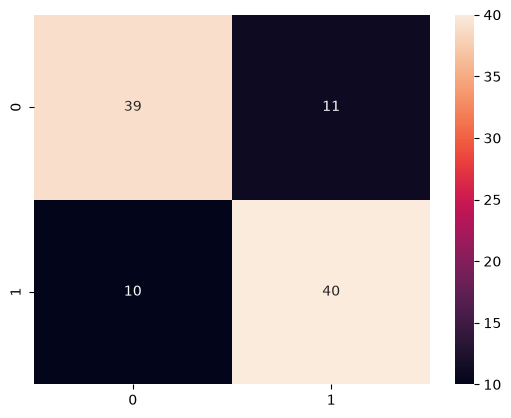

In [217]:
import seaborn as sns
sns.heatmap(co, annot=True) #heatmap for metrics visulaization

In [218]:
import warnings
warnings.filterwarnings("ignore")

<Axes: xlabel='technical_skills', ylabel='Density'>

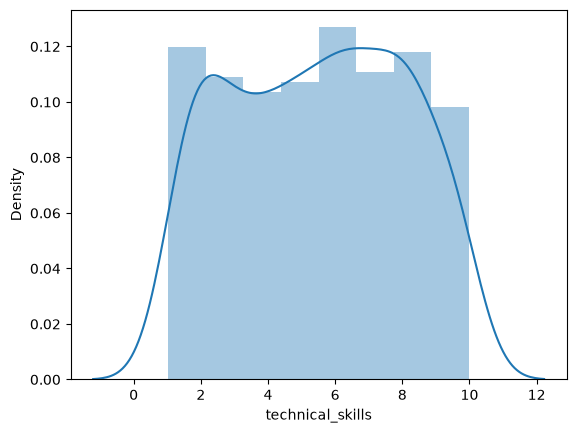

In [219]:
sns.distplot(df['technical_skills'])

#### 7. Dump the model, scaler and encoder as .pkl files

In [220]:
joblib.dump(model, 'placement_model.pkl') #dumped our model

['placement_model.pkl']

In [221]:
joblib.dump(scaler, 'placement_model_scaler.pkl') #dumped our scaler

['placement_model_scaler.pkl']

In [222]:
joblib.dump(le_extracaricular, 'le_extracaricular.pkl')
joblib.dump(le_department, 'le_department.pkl')

['le_department.pkl']